In [1]:
import glob, os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import rankdata

sc.settings.verbosity = 1
np.random.seed(0)

# Look for the data file in the project folder and in Downloads
home = os.path.expanduser('~')
candidates = (glob.glob('**/E9.5_E1S1*.h5ad', recursive=True)
              + glob.glob(f'{home}/Downloads/**/E9.5_E1S1*.h5ad', recursive=True)
              + glob.glob('/kaggle/input/**/E9.5_E1S1*.h5ad', recursive=True))
if not candidates:
    raise FileNotFoundError('Could not find E9.5_E1S1 .h5ad — put it in the notebook folder or Downloads')
path = candidates[0]

OUT = '/kaggle/working' if os.path.exists('/kaggle/input') else 'outputs'
os.makedirs(OUT, exist_ok=True)

print('Loading', path)
adata = sc.read_h5ad(path)
adata.var_names_make_unique()
print(adata)
print('obs columns :', adata.obs.columns.tolist())
print('layers      :', list(adata.layers.keys()))
print('obsm        :', list(adata.obsm.keys()))

Loading E9.5_E1S1.MOSTA.h5ad
AnnData object with n_obs × n_vars = 5913 × 25568
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'annotation', 'Regulon - 2310011J03Rik', 'Regulon - 5730507C01Rik', 'Regulon - Alx1', 'Regulon - Alx3', 'Regulon - Alx4', 'Regulon - Ar', 'Regulon - Arid3a', 'Regulon - Arid3c', 'Regulon - Arnt2', 'Regulon - Arx', 'Regulon - Ascl1', 'Regulon - Atf1', 'Regulon - Atf4', 'Regulon - Atf5', 'Regulon - Atf6', 'Regulon - Atf7', 'Regulon - Bach1', 'Regulon - Bach2', 'Regulon - Barhl1', 'Regulon - Barx1', 'Regulon - Batf', 'Regulon - Bcl11a', 'Regulon - Bcl3', 'Regulon - Bcl6', 'Regulon - Bcl6b', 'Regulon - Bclaf1', 'Regulon - Bdp1', 'Regulon - Bhlha15', 'Regulon - Bhlhe22', 'Regulon - Bhlhe23', 'Regulon - Bhlhe41', 'Regulon - Bmyc', 'Regulon - Boll', 'Regulon - Bptf', 'Regulon - Brca1', 'Regulon - Brf1', 'Regulon - Brf2', 'Regulon - Bsx', 'Regulon - Cdx1', 'Regulon - Cdx2', 'Regulon - Cebpa', 'Regulon - Cebpz', 'Regulon - 

## 1. Look at the tissue
Check that `obsm['spatial']` exists and see which tissue annotations are available — we will use one of them as the **root** (where development starts).

annotation
Brain                1518
Neural crest         1008
Cavity                882
AGM                   452
Heart                 382
Mesenchyme            337
Connective tissue     283
Dermomyotome          273
Sclerotome            244
Notochord             236
Branchial arch        200
Liver                  98
Name: count, dtype: int64


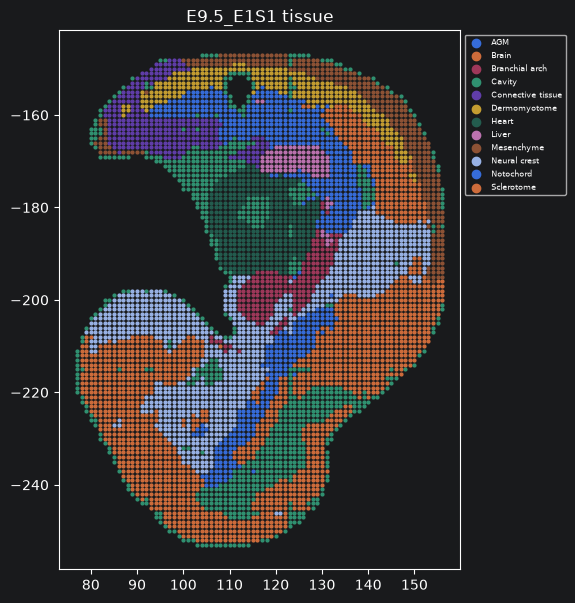

In [2]:
ANN = 'annotation'
adata.obs[ANN] = adata.obs[ANN].astype('category')
print(adata.obs[ANN].value_counts())

coords = np.asarray(adata.obsm['spatial'])[:, :2]
fig, ax = plt.subplots(figsize=(6, 7))
for lab in adata.obs[ANN].cat.categories:
    m = (adata.obs[ANN] == lab).values
    ax.scatter(coords[m, 0], coords[m, 1], s=4, label=lab)
ax.legend(fontsize=6, markerscale=3, bbox_to_anchor=(1, 1))
ax.set_aspect('equal')
ax.set_title('E9.5_E1S1 tissue')
plt.show()

## 2. Preprocess (done once, shared by all methods)
Use raw counts if they are stored in a layer, then the standard steps: normalise → log → highly variable genes → PCA → kNN graph.

In [3]:
if 'count' in adata.layers:
    adata.X = adata.layers['count'].copy()
adata.layers['counts'] = adata.X.copy()

sc.pp.filter_genes(adata, min_cells=10)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
sc.tl.pca(adata, n_comps=30, mask_var='highly_variable')
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
print(adata)

/Users/riyaansharma/PycharmProjects/WelcomeScreen/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


AnnData object with n_obs × n_vars = 5913 × 20055
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'annotation', 'Regulon - 2310011J03Rik', 'Regulon - 5730507C01Rik', 'Regulon - Alx1', 'Regulon - Alx3', 'Regulon - Alx4', 'Regulon - Ar', 'Regulon - Arid3a', 'Regulon - Arid3c', 'Regulon - Arnt2', 'Regulon - Arx', 'Regulon - Ascl1', 'Regulon - Atf1', 'Regulon - Atf4', 'Regulon - Atf5', 'Regulon - Atf6', 'Regulon - Atf7', 'Regulon - Bach1', 'Regulon - Bach2', 'Regulon - Barhl1', 'Regulon - Barx1', 'Regulon - Batf', 'Regulon - Bcl11a', 'Regulon - Bcl3', 'Regulon - Bcl6', 'Regulon - Bcl6b', 'Regulon - Bclaf1', 'Regulon - Bdp1', 'Regulon - Bhlha15', 'Regulon - Bhlhe22', 'Regulon - Bhlhe23', 'Regulon - Bhlhe41', 'Regulon - Bmyc', 'Regulon - Boll', 'Regulon - Bptf', 'Regulon - Brca1', 'Regulon - Brf1', 'Regulon - Brf2', 'Regulon - Bsx', 'Regulon - Cdx1', 'Regulon - Cdx2', 'Regulon - Cebpa', 'Regulon - Cebpz', 'Regulon - Chd1', 'Regulon - Clock', 'Re

## 3. Base method #1: diffusion pseudotime on PCA (aspatial)
Pseudotime needs a **root**. Set `ROOT_TYPE` to a tissue label from the list above (leave `None` to use the most extreme cell on diffusion component 1).

Note: a whole E9.5 embryo contains many lineages at once, so one global pseudotime is crude. That is fine for building the pipeline; later we will restrict to one tissue region with a clearer progression.

In [4]:
LINEAGE = ['Neural crest', 'Branchial arch', 'Mesenchyme']
ROOT_TYPE = 'Neural crest'

ad = adata[adata.obs[ANN].isin(LINEAGE)].copy()
ad.obs[ANN] = ad.obs[ANN].cat.remove_unused_categories()
print(ad.obs[ANN].value_counts())

ad.X = ad.layers['count'].copy()
sc.pp.filter_genes(ad, min_cells=10)
sc.pp.normalize_total(ad, target_sum=1e4)
sc.pp.log1p(ad)
sc.pp.highly_variable_genes(ad, n_top_genes=2000)
sc.tl.pca(ad, n_comps=30, mask_var='highly_variable')
sc.pp.neighbors(ad, n_neighbors=15, n_pcs=30)
print(ad)

annotation
Neural crest      1008
Mesenchyme         337
Branchial arch     200
Name: count, dtype: int64
AnnData object with n_obs × n_vars = 1545 × 16491
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'annotation', 'Regulon - 2310011J03Rik', 'Regulon - 5730507C01Rik', 'Regulon - Alx1', 'Regulon - Alx3', 'Regulon - Alx4', 'Regulon - Ar', 'Regulon - Arid3a', 'Regulon - Arid3c', 'Regulon - Arnt2', 'Regulon - Arx', 'Regulon - Ascl1', 'Regulon - Atf1', 'Regulon - Atf4', 'Regulon - Atf5', 'Regulon - Atf6', 'Regulon - Atf7', 'Regulon - Bach1', 'Regulon - Bach2', 'Regulon - Barhl1', 'Regulon - Barx1', 'Regulon - Batf', 'Regulon - Bcl11a', 'Regulon - Bcl3', 'Regulon - Bcl6', 'Regulon - Bcl6b', 'Regulon - Bclaf1', 'Regulon - Bdp1', 'Regulon - Bhlha15', 'Regulon - Bhlhe22', 'Regulon - Bhlhe23', 'Regulon - Bhlhe41', 'Regulon - Bmyc', 'Regulon - Boll', 'Regulon - Bptf', 'Regulon - Brca1', 'Regulon - Brf1', 'Regulon - Brf2', 'Regulon - Bsx', 'Regulon

In [5]:
print(ad.shape)
print(ad.obs['annotation'].value_counts())

(1545, 16491)
annotation
Neural crest      1008
Mesenchyme         337
Branchial arch     200
Name: count, dtype: int64


KeyError: 't_dpt_pca'

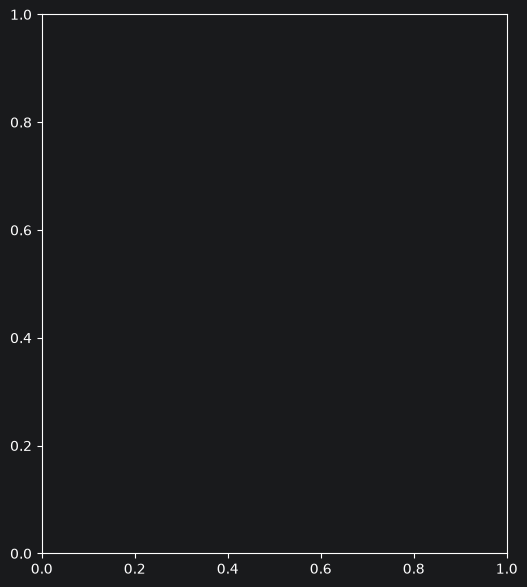

In [6]:
fig, ax = plt.subplots(figsize=(6, 7))
sca = ax.scatter(coords[:, 0], coords[:, 1], c=adata.obs['t_dpt_pca'], s=4, cmap='viridis')
ax.scatter(coords[root, 0], coords[root, 1], c='red', s=80, marker='*', label='root')
plt.colorbar(sca, label='rank-scaled pseudotime'); ax.legend()
ax.set_aspect('equal'); ax.set_title('Base method 1: DPT on PCA (aspatial)'); plt.show()